In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("../data/processed/groundwater_nitrate_annual.csv")

df.head()

,Messstellencode,Jahr,Anzahl Messungen,Jahresmittelwert in mg Nitrat pro Liter,Messstellenname,Wasserkörpercode,Wasserkörpername,Probenahmetiefe in m,Länge in Grad (ETRS89),Breite in Grad (ETRS89)
0,BB_25481088,2012,1,0.15,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854
1,BB_25481088,2013,1,1.07,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854
2,BB_25481088,2014,1,0.31,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854
3,BB_25481088,2015,2,0.15,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854
4,BB_25481088,2016,1,0.16,Milow OP,DEGB_DEBB_ODR_OF_2,Uecker,34.9,13.82148,53.475854


In [5]:
df.shape

(7311, 10)

In [6]:
df.columns

Index(['Messstellencode', 'Jahr', 'Anzahl Messungen',
       'Jahresmittelwert in mg Nitrat pro Liter', 'Messstellenname',
       'Wasserkörpercode', 'Wasserkörpername', 'Probenahmetiefe in m',
       'Länge in Grad (ETRS89)', 'Breite in Grad (ETRS89)'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7311 entries, 0 to 7310
Data columns (total 10 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Messstellencode                          7311 non-null   str    
 1   Jahr                                     7311 non-null   int64  
 2   Anzahl Messungen                         7311 non-null   int64  
 3   Jahresmittelwert in mg Nitrat pro Liter  7311 non-null   float64
 4   Messstellenname                          7251 non-null   str    
 5   Wasserkörpercode                         7311 non-null   str    
 6   Wasserkörpername                         7311 non-null   str    
 7   Probenahmetiefe in m                     7311 non-null   float64
 8   Länge in Grad (ETRS89)                   7311 non-null   float64
 9   Breite in Grad (ETRS89)                  7311 non-null   float64
dtypes: float64(4), int64(2), str(4)
memory usage: 571.3 KB


In [8]:
df.isnull().sum()

Messstellencode                             0
Jahr                                        0
Anzahl Messungen                            0
Jahresmittelwert in mg Nitrat pro Liter     0
Messstellenname                            60
Wasserkörpercode                            0
Wasserkörpername                            0
Probenahmetiefe in m                        0
Länge in Grad (ETRS89)                      0
Breite in Grad (ETRS89)                     0
dtype: int64

In [9]:
df[df["Messstellenname"].isnull()]["Messstellencode"].value_counts()

Messstellencode
HH_1947     11
HH_5947     11
HH_5346      8
SL_00765     8
SL_00890     6
SL_01146     6
SL_01559     6
SL_S0527     4
Name: count, dtype: int64

In [10]:
df.duplicated(
    subset=["Messstellencode", "Jahr"]
).sum()

np.int64(0)

In [11]:
df.describe()

,Jahr,Anzahl Messungen,Jahresmittelwert in mg Nitrat pro Liter,Probenahmetiefe in m,Länge in Grad (ETRS89),Breite in Grad (ETRS89)
count,7311.000000,7311.000000,7311.000000,7311.000000,7311.000000,7311.000000
mean,2017.040760,1.445493,38.176549,12.145178,10.424329,51.177886
std,3.170699,0.964771,46.964856,14.552963,2.027866,1.889703
min,2012.000000,1.000000,0.020000,0.000000,6.039740,47.463694
25%,2014.000000,1.000000,1.700000,3.000000,8.854437,49.594364
50%,2017.000000,1.000000,24.820000,8.000000,10.439818,51.365931
75%,2020.000000,2.000000,53.100000,16.000000,12.057866,52.720165
max,2022.000000,14.000000,776.320000,115.000000,14.588411,54.807137


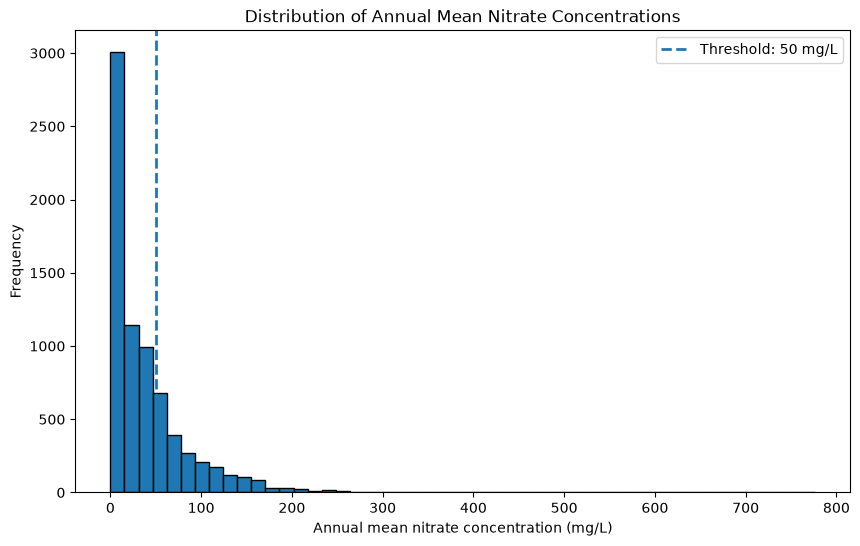

In [13]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["Jahresmittelwert in mg Nitrat pro Liter"],
    bins=50,
    edgecolor="black"
)

plt.axvline(
    x=50,
    linestyle="--",
    linewidth=2,
    label="Threshold: 50 mg/L"
)

plt.xlabel("Annual mean nitrate concentration (mg/L)")
plt.ylabel("Frequency")
plt.title("Distribution of Annual Mean Nitrate Concentrations")
plt.legend()

plt.show()

In [14]:
(df["Jahresmittelwert in mg Nitrat pro Liter"] > 50).sum()

np.int64(1968)

In [15]:
(df["Jahresmittelwert in mg Nitrat pro Liter"] > 50).mean() * 100

np.float64(26.91834222404596)

In [16]:
yearly_trend = (
    df.groupby("Jahr")["Jahresmittelwert in mg Nitrat pro Liter"]
    .mean()
)

yearly_trend

Jahr
2012    40.814268
2013    41.671477
2014    41.338134
2015    39.667088
2016    38.718380
2017    36.554664
2018    36.953494
2019    36.781051
2020    37.413757
2021    35.158717
2022    35.164305
Name: Jahresmittelwert in mg Nitrat pro Liter, dtype: float64

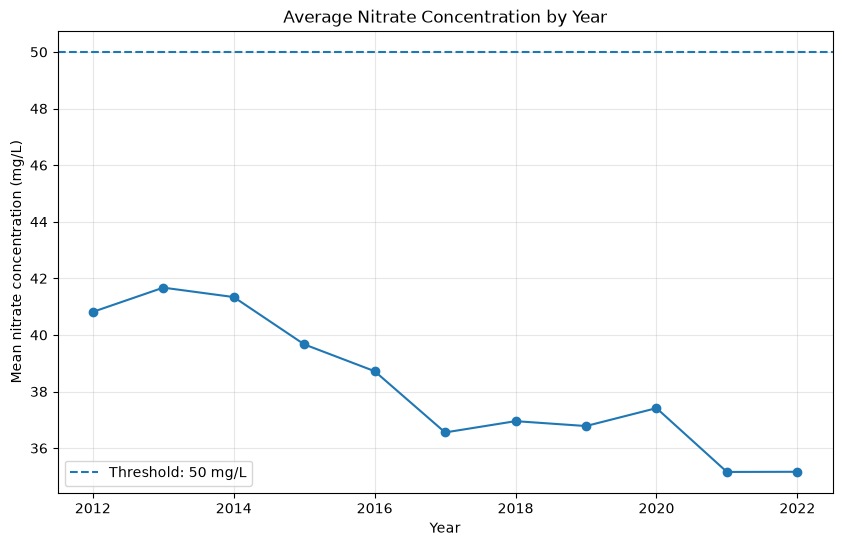

In [17]:
plt.figure(figsize=(10, 6))

plt.plot(
    yearly_trend.index,
    yearly_trend.values,
    marker="o"
)

plt.axhline(
    y=50,
    linestyle="--",
    label="Threshold: 50 mg/L"
)

plt.xlabel("Year")
plt.ylabel("Mean nitrate concentration (mg/L)")
plt.title("Average Nitrate Concentration by Year")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [18]:
df["Above_50"] = (
    df["Jahresmittelwert in mg Nitrat pro Liter"] > 50
)

In [19]:
yearly_exceedance = (
    df.groupby("Jahr")["Above_50"]
    .mean()
    .mul(100)
)

yearly_exceedance

Jahr
2012    30.335366
2013    29.542097
2014    28.708134
2015    28.351310
2016    27.098675
2017    26.158445
2018    26.807229
2019    25.000000
2020    25.142857
2021    24.635569
2022    24.556213
Name: Above_50, dtype: float64

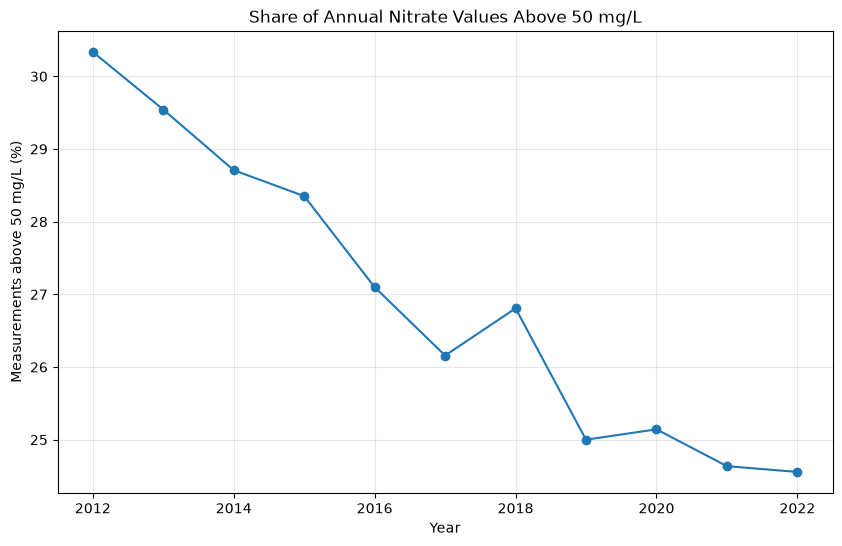

In [20]:
plt.figure(figsize=(10, 6))

plt.plot(
    yearly_exceedance.index,
    yearly_exceedance.values,
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Measurements above 50 mg/L (%)")
plt.title("Share of Annual Nitrate Values Above 50 mg/L")

plt.grid(alpha=0.3)

plt.show()

In [21]:
station_hotspots = (
    df.groupby("Messstellencode")
    .agg(
        mean_nitrate=("Jahresmittelwert in mg Nitrat pro Liter", "mean"),
        max_nitrate=("Jahresmittelwert in mg Nitrat pro Liter", "max"),
        years_above_50=("Above_50", "sum"),
        years_observed=("Jahr", "count")
    )
    .sort_values("mean_nitrate", ascending=False)
)

station_hotspots.head(10)

,mean_nitrate,max_nitrate,years_above_50,years_observed
Messstellencode,,,,
ST_37340030,328.900000,370.00,5,5
MV_26370007,327.415000,776.32,10,10
NW_080201570,250.390909,304.58,11,11
RP_2391181500,239.302727,299.50,11,11
NI_40507271,237.820909,337.12,11,11
MV_26510010,205.570000,245.43,10,10
NI_200001392,185.215455,230.20,11,11
BB_41476054,183.936364,284.50,11,11
RP_2395164700,183.181818,215.00,11,11


In [22]:
station_hotspots["exceedance_rate"] = (
    station_hotspots["years_above_50"]
    / station_hotspots["years_observed"]
    * 100
)

station_hotspots.head(10)

,mean_nitrate,max_nitrate,years_above_50,years_observed,exceedance_rate
Messstellencode,,,,,
ST_37340030,328.900000,370.00,5,5,100.0
MV_26370007,327.415000,776.32,10,10,100.0
NW_080201570,250.390909,304.58,11,11,100.0
RP_2391181500,239.302727,299.50,11,11,100.0
NI_40507271,237.820909,337.12,11,11,100.0
MV_26510010,205.570000,245.43,10,10,100.0
NI_200001392,185.215455,230.20,11,11,100.0
BB_41476054,183.936364,284.50,11,11,100.0
RP_2395164700,183.181818,215.00,11,11,100.0


In [23]:
persistent_hotspots = station_hotspots[
    station_hotspots["years_observed"] >= 5
].sort_values(
    ["exceedance_rate", "mean_nitrate"],
    ascending=[False, False]
)

persistent_hotspots.head(10)

,mean_nitrate,max_nitrate,years_above_50,years_observed,exceedance_rate
Messstellencode,,,,,
ST_37340030,328.900000,370.00,5,5,100.0
MV_26370007,327.415000,776.32,10,10,100.0
NW_080201570,250.390909,304.58,11,11,100.0
RP_2391181500,239.302727,299.50,11,11,100.0
NI_40507271,237.820909,337.12,11,11,100.0
MV_26510010,205.570000,245.43,10,10,100.0
NI_200001392,185.215455,230.20,11,11,100.0
BB_41476054,183.936364,284.50,11,11,100.0
RP_2395164700,183.181818,215.00,11,11,100.0


In [24]:
station_info = (
    df[
        [
            "Messstellencode",
            "Messstellenname",
            "Wasserkörpercode",
            "Wasserkörpername",
            "Länge in Grad (ETRS89)",
            "Breite in Grad (ETRS89)"
        ]
    ]
    .drop_duplicates(subset="Messstellencode")
)

In [25]:
persistent_hotspots = (
    persistent_hotspots
    .reset_index()
    .merge(
        station_info,
        on="Messstellencode",
        how="left"
    )
)

persistent_hotspots.head(10)

,Messstellencode,mean_nitrate,max_nitrate,years_above_50,years_observed,exceedance_rate,Messstellenname,Wasserkörpercode,Wasserkörpername,Länge in Grad (ETRS89),Breite in Grad (ETRS89)
0,ST_37340030,328.900000,370.00,5,5,100.0,Wedringen Kanal Süd,DEGB_DEST_OT-4,Flechtinger Höhenzug,11.469874,52.254732
1,MV_26370007,327.415000,776.32,10,10,100.0,Suckow/Parchim,DEGB_DEMV_MEL_EO_12_16,Mittelelde,11.961610,53.307232
2,NW_080201570,250.390909,304.58,11,11,100.0,FLOTHEND 200,DEGB_DENW_286_06,Hauptterrassen des Rheinlandes,6.271104,51.295740
3,RP_2391181500,239.302727,299.50,11,11,100.0,"1484 I, Gönnheim",DEGB_DERP_28,"Rhein, RLP, 5",8.260970,49.453447
4,NI_40507271,237.820909,337.12,11,11,100.0,Echtelerfeld I,DEGB_DENI_928_26,Untere Vechte links,6.812831,52.583403
5,MV_26510010,205.570000,245.43,10,10,100.0,Hohenholz OP,DEGB_DEMV_ODR_OF_16_16,Randow/Linken,14.315091,53.347762
6,NI_200001392,185.215455,230.20,11,11,100.0,Nordel I,DEGB_DENI_4_2412,Große Aue Lockergestein rechts,8.717169,52.451703
7,BB_41476054,183.936364,284.50,11,11,100.0,Kemlitz OP,DEGB_DEBB_HAV_DA_2,Dahme 2,13.535033,51.855877
8,RP_2395164700,183.181818,215.00,11,11,100.0,"2017, Mettenheim",DEGB_DERP_21,"Rhein, RLP, 7",8.352142,49.739840
9,ST_37375220,174.792000,201.89,10,10,100.0,Pietzpuhl - Güte,DEGB_DEST_HAV_UH_7,"Burg-Ziesar Fläming, Moränenlandschaft",11.844619,52.208782


In [26]:
station_variability = (
    df.groupby("Messstellencode")
    .agg(
        mean_nitrate=("Jahresmittelwert in mg Nitrat pro Liter", "mean"),
        std_nitrate=("Jahresmittelwert in mg Nitrat pro Liter", "std"),
        min_nitrate=("Jahresmittelwert in mg Nitrat pro Liter", "min"),
        max_nitrate=("Jahresmittelwert in mg Nitrat pro Liter", "max"),
        years_observed=("Jahr", "count")
    )
)

station_variability.head()

,mean_nitrate,std_nitrate,min_nitrate,max_nitrate,years_observed
Messstellencode,,,,,
BB_25481088,0.205455,0.297401,0.04,1.07,11
BB_25501075,79.284545,15.332991,40.50,96.00,11
BB_26390030,0.120000,0.113578,0.04,0.40,11
BB_26471092,0.314545,0.491332,0.03,1.70,11
BB_26480022,0.134545,0.191800,0.03,0.69,11


In [27]:
station_variability["cv_nitrate"] = (
    station_variability["std_nitrate"]
    / station_variability["mean_nitrate"]
)

station_variability.head()

,mean_nitrate,std_nitrate,min_nitrate,max_nitrate,years_observed,cv_nitrate
Messstellencode,,,,,,
BB_25481088,0.205455,0.297401,0.04,1.07,11,1.447526
BB_25501075,79.284545,15.332991,40.50,96.00,11,0.193392
BB_26390030,0.120000,0.113578,0.04,0.40,11,0.946485
BB_26471092,0.314545,0.491332,0.03,1.70,11,1.562039
BB_26480022,0.134545,0.191800,0.03,0.69,11,1.425541


In [28]:
station_variability_longterm = (
    station_variability[
        station_variability["years_observed"] >= 5
    ]
    .sort_values("std_nitrate", ascending=False)
)

station_variability_longterm.head(10)

,mean_nitrate,std_nitrate,min_nitrate,max_nitrate,years_observed,cv_nitrate
Messstellencode,,,,,,
MV_26370007,327.415000,192.770969,128.80,776.32,10,0.588766
SH_4645,118.525455,74.203085,37.10,251.44,11,0.626052
TH_111975,22.180909,68.928460,0.22,230.00,11,3.107558
ST_36350084,116.446364,64.960780,32.00,210.21,11,0.557860
SH_5242,94.439091,64.786042,31.25,254.98,11,0.686009
BB_30448600,164.012727,62.080074,101.00,275.50,11,0.378508
NI_400080032,108.400000,61.862851,37.19,247.90,11,0.570691
NI_40507271,237.820909,56.276208,166.00,337.12,11,0.236633
BB_41476054,183.936364,55.603975,127.75,284.50,11,0.302300


In [29]:
stations_to_check = ["MV_26370007", "TH_111975"]

df[
    df["Messstellencode"].isin(stations_to_check)
][
    [
        "Messstellencode",
        "Messstellenname",
        "Jahr",
        "Jahresmittelwert in mg Nitrat pro Liter"
    ]
].sort_values(
    ["Messstellencode", "Jahr"]
)

,Messstellencode,Messstellenname,Jahr,Jahresmittelwert in mg Nitrat pro Liter
3395,MV_26370007,Suckow/Parchim,2012,166.01
3396,MV_26370007,Suckow/Parchim,2013,191.22
3397,MV_26370007,Suckow/Parchim,2015,234.76
3398,MV_26370007,Suckow/Parchim,2016,344.89
3399,MV_26370007,Suckow/Parchim,2017,128.80
3400,MV_26370007,Suckow/Parchim,2018,479.95
3401,MV_26370007,Suckow/Parchim,2019,417.29
3402,MV_26370007,Suckow/Parchim,2020,776.32
3403,MV_26370007,Suckow/Parchim,2021,294.44
3404,MV_26370007,Suckow/Parchim,2022,240.47


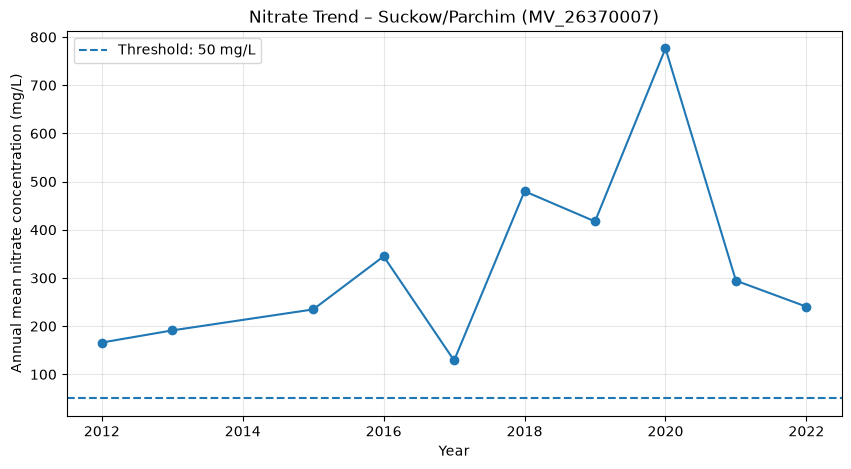

In [30]:
station_mv = df[df["Messstellencode"] == "MV_26370007"]

plt.figure(figsize=(10, 5))

plt.plot(
    station_mv["Jahr"],
    station_mv["Jahresmittelwert in mg Nitrat pro Liter"],
    marker="o"
)

plt.axhline(
    y=50,
    linestyle="--",
    label="Threshold: 50 mg/L"
)

plt.xlabel("Year")
plt.ylabel("Annual mean nitrate concentration (mg/L)")
plt.title("Nitrate Trend – Suckow/Parchim (MV_26370007)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

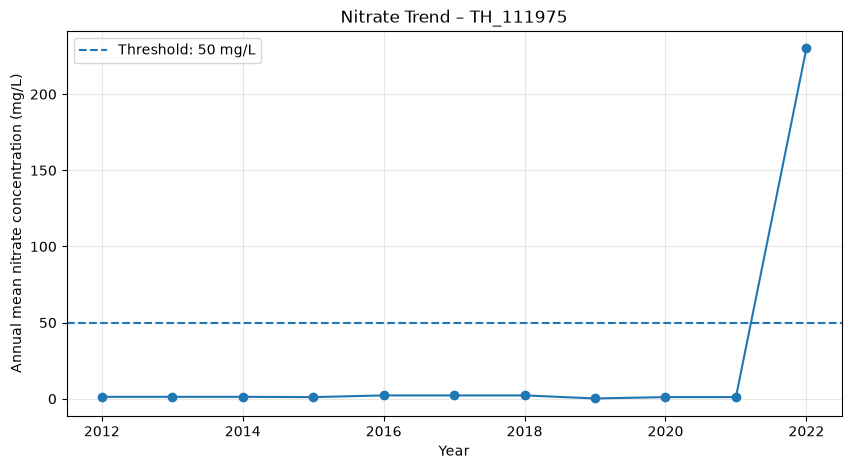

In [31]:
station_th = df[df["Messstellencode"] == "TH_111975"]

plt.figure(figsize=(10, 5))

plt.plot(
    station_th["Jahr"],
    station_th["Jahresmittelwert in mg Nitrat pro Liter"],
    marker="o"
)

plt.axhline(
    y=50,
    linestyle="--",
    label="Threshold: 50 mg/L"
)

plt.xlabel("Year")
plt.ylabel("Annual mean nitrate concentration (mg/L)")
plt.title("Nitrate Trend – TH_111975")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [32]:
df[
    (df["Messstellencode"] == "TH_111975") &
    (df["Jahr"] == 2022)
][
    [
        "Messstellencode",
        "Messstellenname",
        "Jahr",
        "Anzahl Messungen",
        "Jahresmittelwert in mg Nitrat pro Liter"
    ]
]

,Messstellencode,Messstellenname,Jahr,Anzahl Messungen,Jahresmittelwert in mg Nitrat pro Liter
6784,TH_111975,Hy Schleusingen 121/1989 (Hinternah),2022,1,230.0


In [33]:
df["Anzahl Messungen"].value_counts().sort_index()

Anzahl Messungen
1     5067
2     1757
3      220
4      189
5       34
6       19
7        4
8        1
9        1
11       3
12       6
13       3
14       7
Name: count, dtype: int64

In [34]:
(df["Anzahl Messungen"] == 1).sum()

np.int64(5067)

In [35]:
df[
    df["Jahresmittelwert in mg Nitrat pro Liter"] > 200
][
    [
        "Messstellencode",
        "Messstellenname",
        "Jahr",
        "Anzahl Messungen",
        "Jahresmittelwert in mg Nitrat pro Liter"
    ]
].sort_values(
    "Jahresmittelwert in mg Nitrat pro Liter",
    ascending=False
)

,Messstellencode,Messstellenname,Jahr,Anzahl Messungen,Jahresmittelwert in mg Nitrat pro Liter
3402,MV_26370007,Suckow/Parchim,2020,1,776.32
3400,MV_26370007,Suckow/Parchim,2018,1,479.95
3401,MV_26370007,Suckow/Parchim,2019,2,417.29
6302,ST_37340030,Wedringen Kanal Süd,2015,1,370.00
6303,ST_37340030,Wedringen Kanal Süd,2016,1,350.00
...,...,...,...,...,...
298,BB_33502258,Reichenow OP,2013,1,202.00
5064,RP_2391181500,"1484 I, Gönnheim",2021,1,202.00
5088,RP_2395164700,"2017, Mettenheim",2013,2,202.00
6314,ST_37375220,Pietzpuhl - Güte,2014,2,201.89


In [36]:
extreme_values = df[
    df["Jahresmittelwert in mg Nitrat pro Liter"] > 200
]

print("Number of values > 200 mg/L:", len(extreme_values))
print(
    "Number of stations with values > 200 mg/L:",
    extreme_values["Messstellencode"].nunique()
)

Number of values > 200 mg/L: 77
Number of stations with values > 200 mg/L: 22


In [37]:
extreme_values["Messstellencode"].value_counts().head(15)

Messstellencode
NW_080201570     11
RP_2391181500    10
NI_40507271       8
MV_26370007       7
MV_26510010       6
ST_37340030       5
BB_30448600       4
SN_44420007       4
BB_41476054       3
RP_2395164700     3
BB_33502258       2
HE_12759          2
NI_200001392      2
SH_4645           2
NI_100000840      1
Name: count, dtype: int64